# Pipeline suy luận kiểm tra vật đúc

Nạp trọng số ImprovedCNN đã lưu ở `03_model_evaluation.ipynb`, tiền xử lý một ảnh lỗi trong tập test và hiển thị dự đoán cùng độ tự tin. Hãy chạy cell lưu mô hình ở notebook đánh giá trước.

Ảnh đang kiểm tra: cast_def_0_501.jpeg
Dự đoán: LỖI (Defective) | Độ tự tin: 93.5%


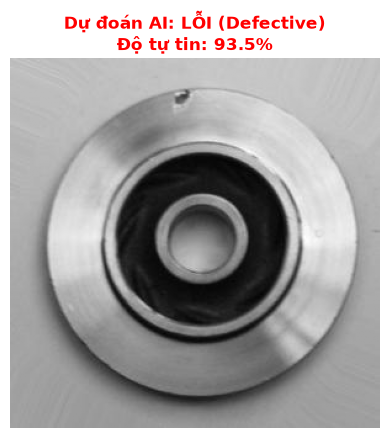

In [4]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms


class ImprovedCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        self.dropout = nn.Dropout(0.4)
        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, 2)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = torch.flatten(x, start_dim=1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)


repo_root = Path.cwd()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent

model_path = repo_root / "final_casting_model.pth"
if not model_path.is_file():
    raise FileNotFoundError(
        f"Không tìm thấy trọng số mô hình: {model_path}. "
        "Hãy chạy cell lưu mô hình trong 03_model_evaluation.ipynb trước."
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ImprovedCNN().to(device)
model.load_state_dict(
    torch.load(model_path, map_location=device, weights_only=True)
)
model.eval()

pipeline_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5]),
])

defect_folder = (
    repo_root / "data" / "casting_data" / "casting_data" / "test" / "def_front"
)
sample_images = sorted(defect_folder.glob("*.jpeg"))
if not sample_images:
    raise FileNotFoundError(
        f"Không tìm thấy ảnh .jpeg nào trong thư mục: {defect_folder}"
    )

sample_image = random.choice(sample_images)
image = Image.open(sample_image).convert("L")
input_tensor = pipeline_transform(image).unsqueeze(0).to(device)

with torch.inference_mode():
    probabilities = torch.softmax(model(input_tensor), dim=1)
    confidence, predicted_class = probabilities.max(dim=1)

class_names = ["LỖI (Defective)", "BÌNH THƯỜNG (OK)"]
class_index = predicted_class.item()
result = class_names[class_index]
confidence_percent = confidence.item() * 100
color = "red" if class_index == 0 else "green"

print(f"Ảnh đang kiểm tra: {sample_image.name}")
print(f"Dự đoán: {result} | Độ tự tin: {confidence_percent:.1f}%")
plt.imshow(image, cmap="gray")
plt.title(
    f"Dự đoán AI: {result}\nĐộ tự tin: {confidence_percent:.1f}%",
    color=color,
    fontweight="bold",
)
plt.axis("off")
plt.show()

🔍 BẮT ĐẦU KIỂM TRA NGẪU NHIÊN 2 VẬT THỂ TRÊN BĂNG CHUYỀN...

👉 Đang đưa vật thể lỗi vào buồng quét camera: cast_def_0_2480.jpeg
Kỳ vọng: LỖI (Defective) | Dự đoán: LỖI (Defective) | Độ tự tin: 100.0% | ĐÚNG


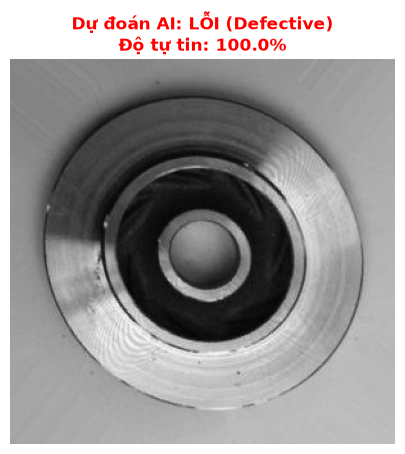


👉 Đang đưa vật thể bình thường vào buồng quét camera: cast_ok_0_8192.jpeg
Kỳ vọng: BÌNH THƯỜNG (OK) | Dự đoán: BÌNH THƯỜNG (OK) | Độ tự tin: 99.6% | ĐÚNG


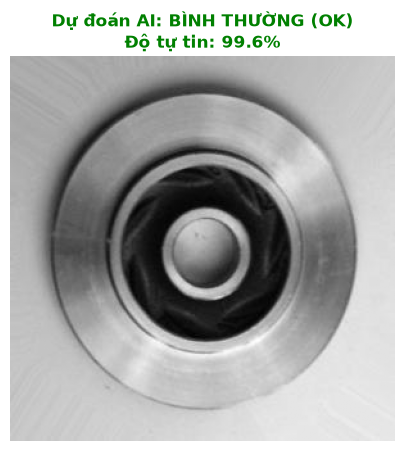

In [5]:
print("🔍 BẮT ĐẦU KIỂM TRA NGẪU NHIÊN 2 VẬT THỂ TRÊN BĂNG CHUYỀN...")

dataset_root = repo_root / "data" / "casting_data" / "casting_data"
defect_folder = dataset_root / "test" / "def_front"
ok_folder = dataset_root / "test" / "ok_front"

defect_images = list(defect_folder.glob("*.jpeg"))
ok_images = list(ok_folder.glob("*.jpeg"))
if not defect_images:
    raise FileNotFoundError(f"Không tìm thấy ảnh .jpeg nào trong thư mục: {defect_folder}")
if not ok_images:
    raise FileNotFoundError(f"Không tìm thấy ảnh .jpeg nào trong thư mục: {ok_folder}")

def inspect_metal_part(image_path, expected_class):
    image = Image.open(image_path).convert("L")
    input_tensor = pipeline_transform(image).unsqueeze(0).to(device)

    with torch.inference_mode():
        probabilities = torch.softmax(model(input_tensor), dim=1)
        confidence, predicted_class = probabilities.max(dim=1)

    class_index = predicted_class.item()
    result = class_names[class_index]
    confidence_percent = confidence.item() * 100
    is_correct = class_index == expected_class
    color = "red" if class_index == 0 else "green"

    print(
        f"Kỳ vọng: {class_names[expected_class]} | "
        f"Dự đoán: {result} | Độ tự tin: {confidence_percent:.1f}% | "
        f"{'ĐÚNG' if is_correct else 'SAI'}"
    )
    plt.figure(figsize=(5, 5))
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Dự đoán AI: {result}\nĐộ tự tin: {confidence_percent:.1f}%",
        color=color,
        fontweight="bold",
    )
    plt.axis("off")
    plt.show()

random_defect = random.choice(defect_images)
random_ok = random.choice(ok_images)

print(f"\n👉 Đang đưa vật thể lỗi vào buồng quét camera: {random_defect.name}")
inspect_metal_part(random_defect, expected_class=0)

print(f"\n👉 Đang đưa vật thể bình thường vào buồng quét camera: {random_ok.name}")
inspect_metal_part(random_ok, expected_class=1)